# WEEK-6

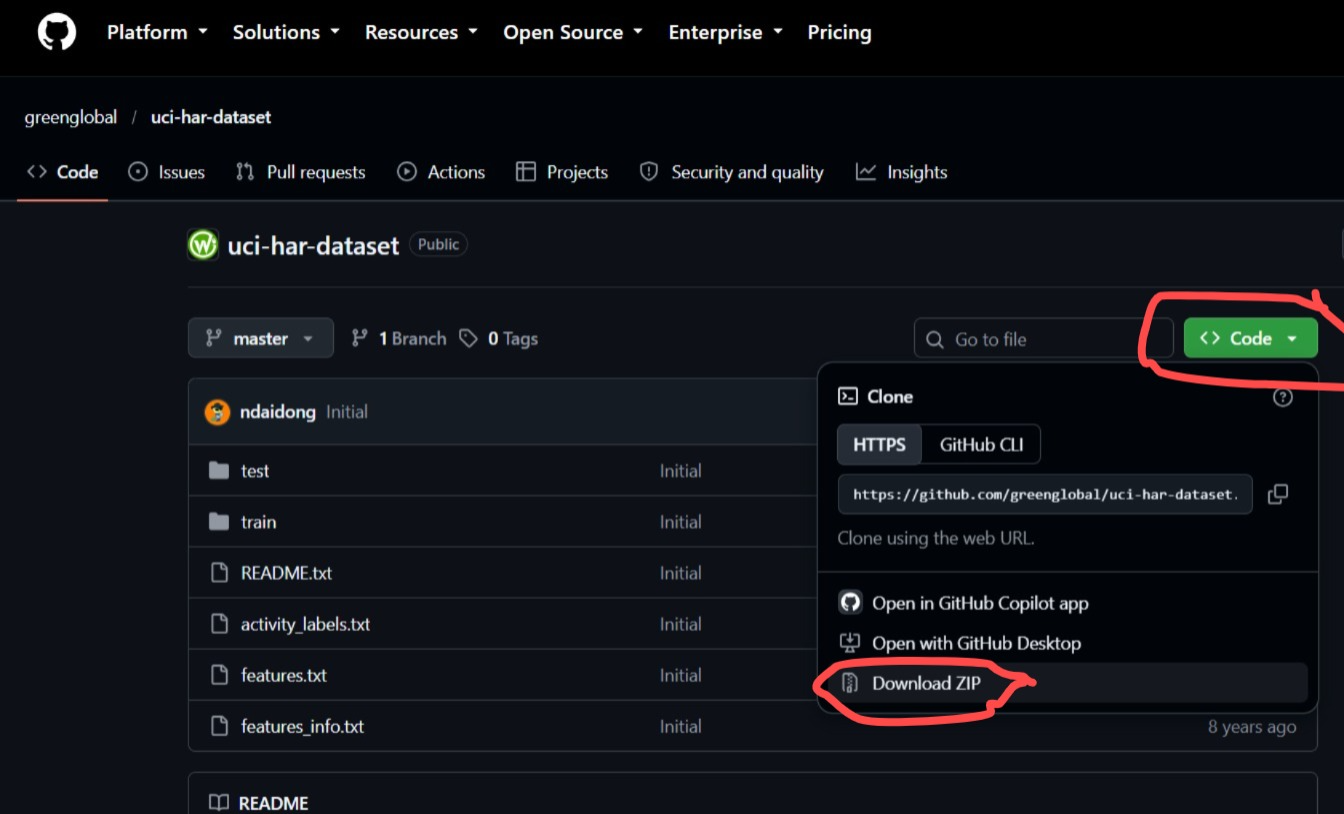

# Dowload Dataset zip file from here: https://github.com/greenglobal/uci-har-dataset

# Next upload the zip file into colab and run the code below

In [ ]:
import zipfile
import os

# Compatible with both local system and Google Colab
if os.path.exists("uci-har-dataset-master.zip"):
    zip_path = "uci-har-dataset-master.zip"
    extract_path = "har_data"
elif os.path.exists("/content/uci-har-dataset-master.zip"):
    zip_path = "/content/uci-har-dataset-master.zip"
    extract_path = "/content/har_data"
else:
    zip_path = "uci-har-dataset-master.zip"
    extract_path = "har_data"

os.makedirs(extract_path, exist_ok=True)

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)
    print("ZIP extracted successfully!")
else:
    print(f"Using already extracted dataset in: {extract_path}")

print("\nExtracted contents:")
if os.path.exists(extract_path):
    for item in os.listdir(extract_path):
        print(item)


ZIP extracted successfully!

Extracted contents:
UCI HAR Dataset.names
uci-har-dataset-master
UCI HAR Dataset.zip


In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_score, recall_score, f1_score
)

# Dataset paths
# Dataset paths (compatible with local folder and Colab)
if os.path.exists("har_data/uci-har-dataset-master"):
    data_path = "har_data/uci-har-dataset-master"
elif os.path.exists("/content/har_data/uci-har-dataset-master"):
    data_path = "/content/har_data/uci-har-dataset-master"
elif os.path.exists("uci-har-dataset-master"):
    data_path = "uci-har-dataset-master"
else:
    data_path = "/content/har_data/uci-har-dataset-master" 

X_train = pd.read_csv(os.path.join(data_path, "train/X_train.txt"), sep=r"\s+", header=None)
X_test = pd.read_csv(os.path.join(data_path, "test/X_test.txt"), sep=r"\s+", header=None)

y_train = np.loadtxt(os.path.join(data_path, "train/y_train.txt"), dtype=int)
y_test = np.loadtxt(os.path.join(data_path, "test/y_test.txt"), dtype=int)

feature_names = pd.read_csv(
    os.path.join(data_path, "features.txt"), sep=r"\s+", header=None
).iloc[:, 1].tolist()

X_train.columns = feature_names
X_test.columns = feature_names

activity_df = pd.read_csv(
    os.path.join(data_path, "activity_labels.txt"),
    sep=r"\s+", header=None, names=["ID", "Activity"]
)
activity_names = dict(zip(activity_df["ID"], activity_df["Activity"]))

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Number of features:", len(feature_names))
print("Activity names:", activity_names)

display(X_train.head())


Training data: (7352, 561)
Testing data: (2947, 561)
Number of features: 561
Activity names: {1: 'WALKING', 2: 'WALKING_UPSTAIRS', 3: 'WALKING_DOWNSTAIRS', 4: 'SITTING', 5: 'STANDING', 6: 'LAYING'}


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892


In [ ]:
# Check data quality
print("Missing values (train):", X_train.isnull().sum().sum())
print("Missing values (test):", X_test.isnull().sum().sum())
print("Duplicate training rows:", X_train.duplicated().sum())
print("Infinite values (train):", np.isinf(X_train.to_numpy()).sum())

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Encode labels from 1–6 to 0–5
y_train_encoded = y_train - 1
y_test_encoded = y_test - 1

print("\nPreprocessing completed!")
print("Training features:", X_train_scaled.shape)
print("Testing features:", X_test_scaled.shape)

Missing values (train): 0
Missing values (test): 0
Duplicate training rows: 0
Infinite values (train): 0

Preprocessing completed!
Training features: (7352, 561)
Testing features: (2947, 561)


# WEEK-7

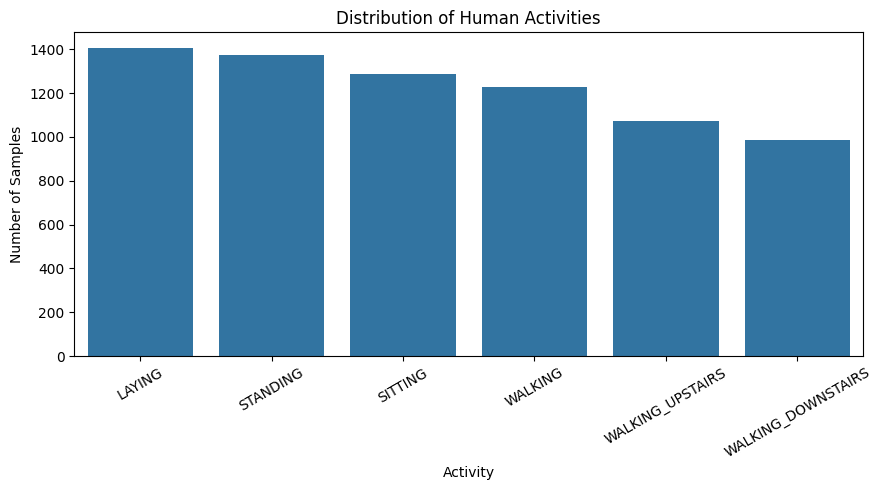

In [ ]:
activity_counts = pd.Series(y_train).map(activity_names).value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(x=activity_counts.index, y=activity_counts.values)
plt.title("Distribution of Human Activities")
plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

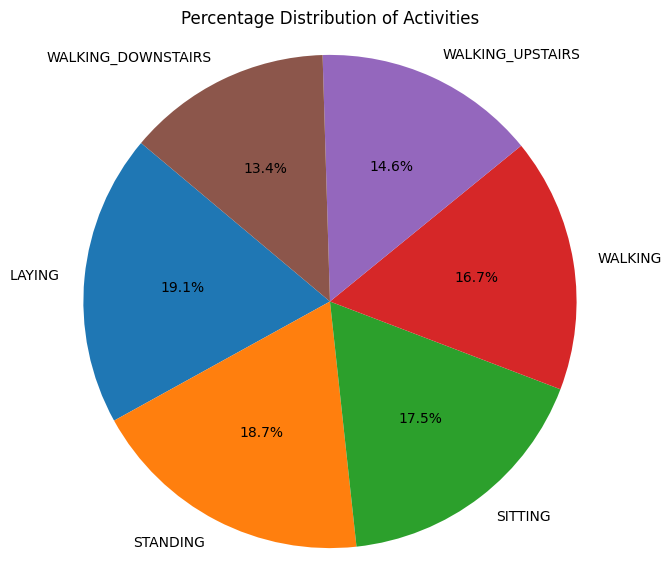

In [ ]:
plt.figure(figsize=(7, 7))
plt.pie(activity_counts.values, labels=activity_counts.index, autopct="%1.1f%%", startangle=140)
plt.title("Percentage Distribution of Activities")
plt.axis("equal")
plt.show()

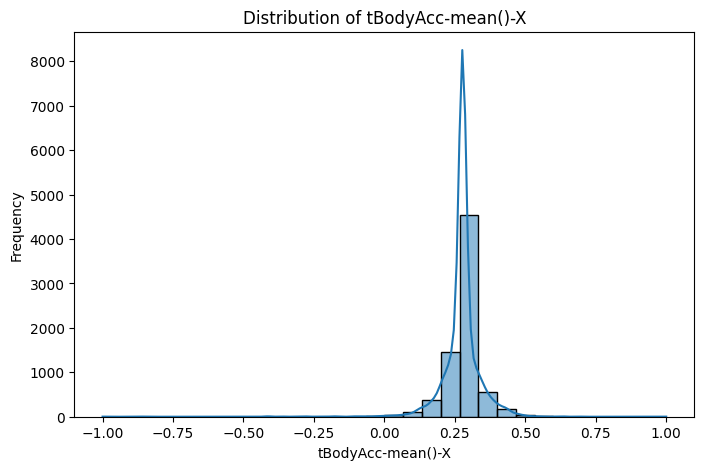

In [ ]:
feature = feature_names[0]

plt.figure(figsize=(8, 5))
sns.histplot(X_train[feature], bins=30, kde=True)
plt.title(f"Distribution of {feature}")
plt.xlabel(feature)
plt.ylabel("Frequency")
plt.show()

# WEEK-8

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "SVM": SVC(kernel="rbf")
}

results = []

for name, model in models.items():
    print("\nTraining:", name)
    model.fit(X_train_scaled, y_train_encoded)
    predictions = model.predict(X_test_scaled)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_encoded, predictions),
        "Precision": precision_score(y_test_encoded, predictions, average="weighted", zero_division=0),
        "Recall": recall_score(y_test_encoded, predictions, average="weighted", zero_division=0),
        "F1 Score": f1_score(y_test_encoded, predictions, average="weighted", zero_division=0)
    })

    print(classification_report(
        y_test_encoded, predictions,
        labels=np.arange(6),
        target_names=[activity_names[i] for i in range(1, 7)],
        zero_division=0
    ))

results_df = pd.DataFrame(results)
display(results_df.sort_values("Accuracy", ascending=False).round(4))


Training: Logistic Regression
                    precision    recall  f1-score   support

           WALKING       0.94      0.99      0.97       496
  WALKING_UPSTAIRS       0.96      0.95      0.95       471
WALKING_DOWNSTAIRS       0.99      0.94      0.96       420
           SITTING       0.97      0.88      0.92       491
          STANDING       0.89      0.97      0.93       532
            LAYING       1.00      0.99      0.99       537

          accuracy                           0.95      2947
         macro avg       0.96      0.95      0.95      2947
      weighted avg       0.96      0.95      0.95      2947


Training: Random Forest
                    precision    recall  f1-score   support

           WALKING       0.89      0.96      0.92       496
  WALKING_UPSTAIRS       0.89      0.90      0.90       471
WALKING_DOWNSTAIRS       0.97      0.86      0.91       420
           SITTING       0.91      0.89      0.90       491
          STANDING       0.90      0.92 

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9549,0.9567,0.9549,0.9548
2,SVM,0.9522,0.9526,0.9522,0.9521
1,Random Forest,0.9260,0.9274,0.9260,0.9260


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D
from tensorflow.keras.layers import Flatten, Dense, Dropout, LSTM
from tensorflow.keras.callbacks import EarlyStopping

# Create training and validation sets
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_scaled, y_train_encoded,
    test_size=0.1, random_state=42,
    stratify=y_train_encoded
)

# Reshape data for CNN and LSTM
X_tr_dl = X_tr.astype("float32").reshape(-1, X_tr.shape[1], 1)
X_val_dl = X_val.astype("float32").reshape(-1, X_val.shape[1], 1)
X_test_dl = X_test_scaled.astype("float32").reshape(-1, X_test_scaled.shape[1], 1)

print("Training:", X_tr_dl.shape)
print("Validation:", X_val_dl.shape)
print("Testing:", X_test_dl.shape)

Training: (6616, 561, 1)
Validation: (736, 561, 1)
Testing: (2947, 561, 1)


In [ ]:
cnn_model = Sequential([
    Input(shape=(561, 1)),
    Conv1D(64, 3, activation="relu"),
    MaxPooling1D(2),
    Dropout(0.3),
    Conv1D(128, 3, activation="relu"),
    MaxPooling1D(2),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(6, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

cnn_history = cnn_model.fit(
    X_tr_dl, y_tr,
    validation_data=(X_val_dl, y_val),
    epochs=15,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

cnn_loss, cnn_accuracy = cnn_model.evaluate(X_test_dl, y_test_encoded, verbose=0)
print("CNN Test Accuracy:", round(cnn_accuracy, 4))

Epoch 1/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 24s 199ms/step - accuracy: 0.8017 - loss: 0.4848 - val_accuracy: 0.9375 - val_loss: 0.1684
Epoch 2/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 17s 159ms/step - accuracy: 0.9395 - loss: 0.1604 - val_accuracy: 0.9592 - val_loss: 0.1016
Epoch 3/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 18s 172ms/step - accuracy: 0.9575 - loss: 0.1099 - val_accuracy: 0.9701 - val_loss: 0.0744
Epoch 4/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 19s 183ms/step - accuracy: 0.9696 - loss: 0.0806 - val_accuracy: 0.9769 - val_loss: 0.0680
Epoch 5/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 18s 170ms/step - accuracy: 0.9745 - loss: 0.0641 - val_accuracy: 0.9891 - val_loss: 0.0405
Epoch 6/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 19s 186ms/step - accuracy: 0.9822 - loss: 0.0508 - val_accuracy: 0.9810 - val_loss: 0.0566
Epoch 7/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 27s 264ms/step - accuracy: 0.9826 - loss: 0.0442 - val_accuracy: 0.9878 - val_loss: 0.0330
Epoch 8/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 34s 190ms/step - accuracy: 0.9816 - loss: 0

In [ ]:
# LSTM
lstm_model = Sequential([
    Input(shape=(561, 1)),
    LSTM(64),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dense(6, activation="softmax")
])

lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

lstm_history = lstm_model.fit(
    X_tr_dl, y_tr,
    validation_data=(X_val_dl, y_val),
    epochs=15,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(
    X_test_dl, y_test_encoded, verbose=0
)

print("LSTM Test Accuracy:", round(lstm_accuracy, 4))

Epoch 1/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 33s 293ms/step - accuracy: 0.4350 - loss: 1.2493 - val_accuracy: 0.5312 - val_loss: 0.9303
Epoch 2/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 31s 294ms/step - accuracy: 0.5922 - loss: 0.9124 - val_accuracy: 0.5992 - val_loss: 0.9950
Epoch 3/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 31s 294ms/step - accuracy: 0.6501 - loss: 0.8030 - val_accuracy: 0.7378 - val_loss: 0.6285
LSTM Test Accuracy: 0.5073


In [ ]:
cnn_predictions = np.argmax(cnn_model.predict(X_test_dl, verbose=0), axis=1)
lstm_predictions = np.argmax(lstm_model.predict(X_test_dl, verbose=0), axis=1)

deep_results = pd.DataFrame([
    {"Model": "CNN", "Accuracy": accuracy_score(y_test_encoded, cnn_predictions)},
    {"Model": "LSTM", "Accuracy": accuracy_score(y_test_encoded, lstm_predictions)}
])

display(deep_results.round(4))

,Model,Accuracy
0,CNN,0.9491
1,LSTM,0.5073


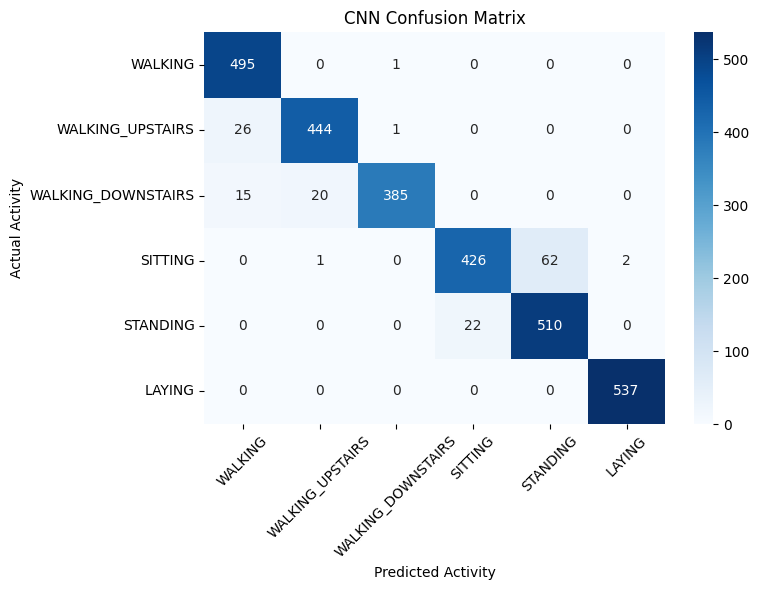

In [ ]:
cm = confusion_matrix(y_test_encoded, cnn_predictions)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=[activity_names[i] for i in range(1, 7)],
    yticklabels=[activity_names[i] for i in range(1, 7)]
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()